# 8.6 — Regularization

**Chapter 8, section 8.3.3**, and the starting point for **Exercise 8**.

**The question this notebook answers:** what does adding a penalty to the objective actually do,
and why does the choice between $\ell_1$ and $\ell_2$ decide which optimizer can be used?

Three things are shown, in order. On linearly separable data an unregularized logistic regression
has **no finite answer** — the coefficients grow forever and the objective keeps improving.
Adding an $\ell_2$ penalty costs two lines on the driver and stops that immediately. Adding an
$\ell_1$ penalty the same way does *not* work, because its derivative does not exist at zero,
which is precisely where the penalty is supposed to do its work — and that single fact is why
Spark switches optimizer when `elasticNetParam` is greater than zero.

In [1]:
# --- CS-777 session setup ------------------------------------------------
import os, tempfile
import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession

SCRATCH = os.environ.get("CS777_SCRATCH", os.path.join(tempfile.gettempdir(), "cs777"))
os.makedirs(SCRATCH, exist_ok=True)

spark = (SparkSession.builder
         .appName("CS777-8.6")
         .master("local[4]")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.warehouse.dir", os.path.join(SCRATCH, "warehouse"))
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")

print("Spark", spark.version)

Spark 4.2.0


---

## 1. The unbounded fit on separable data

Two well-separated blobs, so that some line classifies every training point correctly.

examples: 2000  parameters: 3


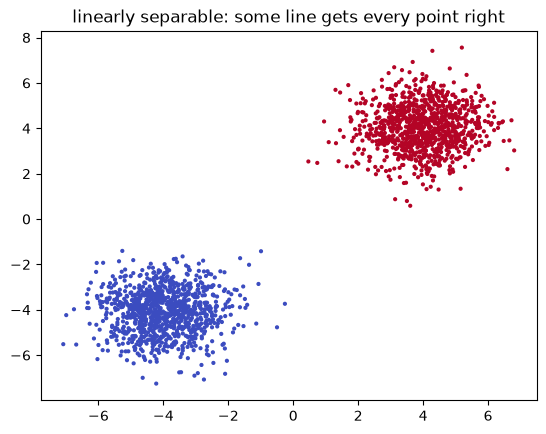

In [2]:
from sklearn.datasets import make_blobs

np.random.seed(777)
X, y = make_blobs(n_samples=[1000, 1000], centers=[[-4, -4], [4, 4]],
                  n_features=2, cluster_std=1.0, random_state=7)

data = [(float(y[i]), np.append(X[i], 1.0)) for i in range(len(y))]   # intercept folded in
sep = sc.parallelize(data, 4)
sep.cache()
d_input = len(sep.first()[1])
print("examples:", sep.count(), " parameters:", d_input)

plt.scatter(X[:, 0], X[:, 1], c=y, s=4, cmap="coolwarm")
plt.title("linearly separable: some line gets every point right")
plt.show()

If a parameter vector $\beta$ classifies every point correctly, then $2\beta$ classifies every
point correctly **and more confidently**, so the likelihood is strictly better. So is $4\beta$, and
so on without end. The maximum likelihood estimate does not exist at any finite value; the
optimizer simply walks outward forever, reporting improvement the whole way.

The loop below is 8.4's `treeAggregate` loop, run for several different iteration budgets, with the
length of the coefficient vector printed alongside the objective.

In [3]:
def train(rdd, n_iter=100, learningRate=1.0, reg=0.0, alpha=0.0,
          penalize_intercept=True, proximal=False, verbose=False):
    # Returns the fitted parameter vector. `reg` is lambda, `alpha` is the L1/L2 mix
    # (0 = pure ridge, 1 = pure lasso), matching regParam and elasticNetParam.
    n = rdd.count()
    beta = np.zeros(d_input)
    mask = np.ones(d_input)
    if not penalize_intercept:
        mask[-1] = 0.0                      # the intercept is the last entry

    for i in range(n_iter):
        b = beta
        gradAndCost = rdd.map(lambda x: (x[0], x[1], np.dot(x[1], b)))\
            .treeAggregate(
                (np.zeros(d_input), 0.0),
                lambda acc, r: (acc[0] + r[1] * (-r[0] + np.exp(r[2]) / (1 + np.exp(r[2]))),
                                acc[1] - r[0] * r[2] + np.log(1 + np.exp(r[2]))),
                lambda a, c: (a[0] + c[0], a[1] + c[1]))

        # --- the two lines the chapter prints: the penalty, added on the driver -------
        cost = gradAndCost[1] / n + reg * (1 - alpha) * (np.square(beta * mask).sum())
        gradient = (1.0 / n) * gradAndCost[0] + 2 * reg * (1 - alpha) * (beta * mask)
        # -----------------------------------------------------------------------------

        beta = beta - learningRate * gradient

        if proximal and alpha > 0:          # the L1 part, applied as a proximal step
            thr = learningRate * reg * alpha * mask
            beta = np.sign(beta) * np.maximum(np.abs(beta) - thr, 0.0)
        elif alpha > 0:                     # the L1 part, applied as a subgradient
            beta = beta - learningRate * reg * alpha * np.sign(beta) * mask

        if verbose and (i % max(1, n_iter // 5) == 0 or i == n_iter - 1):
            print(f"  {i:4} cost={cost:.6f}  ||beta||={np.linalg.norm(beta):.4f}")
    return beta

In [4]:
import pandas as pd

rows = []
for n_iter in (10, 50, 100, 200, 400):
    b = train(sep, n_iter=n_iter, reg=0.0)
    rows.append({"iterations": n_iter, "||beta||": round(float(np.linalg.norm(b)), 4),
                 "beta": np.round(b, 4)})
print(pd.DataFrame(rows).to_string(index=False))

 iterations  ||beta||                      beta
         10    2.8424    [1.9959, 2.0237, -0.0]
         50    2.8434 [1.9965, 2.0246, -0.0001]
        100    2.8447 [1.9972, 2.0257, -0.0002]
        200    2.8472 [1.9987, 2.0278, -0.0005]
        400    2.8522  [2.0016, 2.032, -0.0009]


The direction settles almost at once — the decision boundary is found in the first few iterations —
and after that the length creeps upward and never stops. It creeps *slowly*: gradient descent on
separable data grows the coefficients roughly like $\log t$, so four hundred iterations move
$\lVerteta
Vert$ by a fraction of a percent, and no run of any practical length makes the
divergence obvious from the trace alone.

The trace is therefore the wrong instrument for this. The claim is not that the optimizer diverges
quickly; it is that **there is no finite point for it to converge to**, and that is settled exactly
rather than measured. Take the fitted direction and simply scale it up: if the objective keeps
improving for every $k$, no finite $eta$ can be the maximum-likelihood estimate.

In [5]:
def mean_loss(rdd, beta):
    # The mean negative log-likelihood at a given parameter vector, computed distributed.
    n = rdd.count()
    total = rdd.map(lambda r: (r[0], np.dot(r[1], beta)))\
               .treeAggregate(0.0,
                              lambda acc, r: acc - r[0] * r[1] + np.log(1 + np.exp(r[1])),
                              lambda a, b: a + b)
    return total / n


direction = train(sep, n_iter=100, reg=0.0)
direction = direction / np.linalg.norm(direction)      # a unit vector, the boundary it found

scaled = [{"k": k,
           "||k * beta||": round(float(np.linalg.norm(k * direction)), 1),
           "mean loss": f"{mean_loss(sep, k * direction):.3e}"}
          for k in (1, 2, 5, 10, 25, 50)]
print(pd.DataFrame(scaled).to_string(index=False))

 k  ||k * beta|| mean loss
 1           1.0 5.745e-03
 2           2.0 1.128e-04
 5           5.0 1.249e-07
10          10.0 1.938e-11
25          25.0 0.000e+00
50          50.0 0.000e+00


The loss falls monotonically toward zero, by four orders of magnitude for every doubling or so of
the scale, and the last rows print as exactly zero only because a number that small underflows a
float. It never actually arrives. Every one of those parameter vectors
points in the same direction and draws the same decision boundary; they differ only in how
confident they are, and on separable data more confidence is always rewarded. So the objective has
an infimum it never attains, the maximum-likelihood estimate does not exist at any finite value,
and an optimizer pointed at this problem will report improvement for as long as it is allowed to
run — eventually until the exponentials overflow.

This is the concrete reason the Spark documentation recommends against training without any
regularization at all, especially when training data is limited.

---

## 2. The $\ell_2$ penalty, in two lines

The objective gains a term that depends only on the parameters:

$$f(\beta) = \frac{1}{n}\sum_i L(\beta; x_i, y_i) \;+\; \lambda \lVert \beta \rVert_2^2$$

and the gradient gains its derivative, $2\lambda\beta$. Neither needs the data, so neither costs a
distributed anything — both are computed on the driver after the aggregation returns. Those are
the two lines marked in the training function above.

In [6]:
rows = []
for reg in (0.0, 0.0001, 0.001, 0.01, 0.1):
    b = train(sep, n_iter=200, reg=reg, alpha=0.0)
    rows.append({"lambda (regParam)": reg,
                 "||beta||": round(float(np.linalg.norm(b)), 4),
                 "beta": np.round(b, 4)})
print(pd.DataFrame(rows).to_string(index=False))

 lambda (regParam)  ||beta||                      beta
            0.0000    2.8472 [1.9987, 2.0278, -0.0005]
            0.0001    2.7370 [1.9213, 1.9494, -0.0005]
            0.0010    1.9363 [1.3578, 1.3805, -0.0006]
            0.0100    1.0469   [0.728, 0.7523, 0.0052]
            0.1000    0.6704  [0.4693, 0.4787, 0.0022]


Now the fit has an answer. The penalty grows without bound as the coefficients do, so the total
objective has a finite minimum, and the larger $\lambda$ is the smaller that minimum's coefficients
are. Every coefficient shrinks, and none of them reaches zero.

---

## 3. Why the same trick does not give the lasso

The $\ell_1$ penalty is $\lambda\lVert\beta\rVert_1$ and its derivative is $\lambda\,\mathrm{sign}(\beta)$
— **except at zero, where $\mathrm{sign}$ is undefined**. That would be a technicality if zero were an
unimportant point. It is the opposite: driving coefficients to exactly zero, and thereby selecting
features, is the entire reason to prefer $\ell_1$.

Adding $\lambda\,\mathrm{sign}(\beta)$ to the gradient anyway is the obvious thing to try, and the
`alpha > 0` branch of the training function does exactly that.

Judging whether it worked needs a different dataset. The blobs above are separable by two features,
so no other predictor can earn a coefficient and every method that shrinks looks alike. What a
selection method should be judged on is a problem where the predictors are **graded**: some useful,
some barely, one not at all. The data below is drawn from a logistic model with known coefficients

$$\beta_{\text{true}} = (1.5,\; 1.0,\; 0.5,\; 0.25,\; 0.1,\; 0.0), \qquad \text{intercept} = -1.0$$

so the right answer is known in advance, and a good path should give up `x6` first and `x1` last.

In [7]:
np.random.seed(202)

n_rows = 4000
BETA_TRUE = np.array([1.5, 1.0, 0.5, 0.25, 0.1, 0.0])   # x6 contributes nothing at all
B0_TRUE = -1.0                                          # a genuinely non-zero intercept

feats = np.random.randn(n_rows, len(BETA_TRUE))
logits = feats @ BETA_TRUE + B0_TRUE
probs = 1 / (1 + np.exp(-logits))
labels = (np.random.rand(n_rows) < probs).astype(float)

feats = (feats - feats.mean(axis=0)) / feats.std(axis=0)   # standardize; see the note below

data6 = [(labels[i], np.append(feats[i], 1.0)) for i in range(n_rows)]
rdd6 = sc.parallelize(data6, 4)
rdd6.cache()
d_input = len(rdd6.first()[1])
NAMES = ["x1 (1.5)", "x2 (1.0)", "x3 (0.5)", "x4 (0.25)", "x5 (0.1)", "x6 (0.0)", "intercept"]
print("examples:", rdd6.count(), " parameters:", d_input)
print("class balance:", dict(zip(*np.unique(labels, return_counts=True))))
print("this problem is NOT separable, so it has a finite unregularized optimum")

examples: 4000  parameters: 7
class balance: {np.float64(0.0): np.int64(2592), np.float64(1.0): np.int64(1408)}
this problem is NOT separable, so it has a finite unregularized optimum


The features are **standardized** before training, and that is not decoration. A penalty on the
size of a coefficient is only meaningful if the coefficients are comparable, and a coefficient's
size depends on the units of its feature: a predictor measured in large units gets a small
coefficient and is barely penalized, while one measured in small units gets a large coefficient and
is punished for it. Ridge regression is therefore not invariant under rescaling the inputs. Spark's
estimators standardize automatically — `standardization` defaults to `True` — and a hand-written
implementation has to do it explicitly, as here.

In [8]:
b_subgrad = train(rdd6, n_iter=300, learningRate=1.0, reg=0.01, alpha=1.0, proximal=False)

print(pd.DataFrame({"feature": NAMES, "coefficient": np.round(b_subgrad, 6)}).to_string(index=False))
print("\ncoefficients exactly zero:", int((b_subgrad == 0).sum()))
print("coefficients below 1e-3   :", int((np.abs(b_subgrad) < 1e-3).sum()))

  feature  coefficient
 x1 (1.5)     1.291499
 x2 (1.0)     0.817636
 x3 (0.5)     0.412787
x4 (0.25)     0.112971
 x5 (0.1)     0.075549
 x6 (0.0)     0.002058
intercept    -0.827540

coefficients exactly zero: 0
coefficients below 1e-3   : 0


Not one exact zero. The subgradient step drives the small coefficients *toward* zero and then
leaves them oscillating around it: each step subtracts a fixed amount in the direction of the
current sign, so a coefficient that is nearly zero overshoots to a small value of the opposite
sign, and then overshoots back. It never lands. The feature selection the lasso is chosen for does
not happen.

This is a small, concrete instance of a general fact: a method that builds a smooth local model of
the objective — and L-BFGS, the quasi-Newton optimizer Spark uses by default, is exactly such a
method — cannot be pointed at a function with a kink in it. Spark's answer is to change optimizer,
to **OWL-QN**, whenever `elasticNetParam` is greater than zero.

### The step that does land

The standard fix is not to differentiate the penalty at all. Take the gradient step on the smooth
part of the objective only, then apply the $\ell_1$ penalty as a separate **proximal** operation —
soft-thresholding, which moves each coefficient toward zero by a fixed amount and *clips* it there
rather than letting it pass through:

$$\beta_j \leftarrow \mathrm{sign}(\beta_j)\,\max\left(\lvert\beta_j\rvert - \eta\lambda\alpha,\ 0\right)$$

The $\max$ is what the subgradient step was missing. It is the `proximal` branch of the training
function.

In [9]:
b_prox = train(rdd6, n_iter=300, learningRate=1.0, reg=0.01, alpha=1.0, proximal=True)

print(pd.DataFrame({"feature": NAMES,
                    "subgradient": np.round(b_subgrad, 6),
                    "proximal": np.round(b_prox, 6)}).to_string(index=False))
print("\nexact zeros among the six features, subgradient step:", int((b_subgrad[:-1] == 0).sum()))
print("exact zeros among the six features, proximal step   :", int((b_prox[:-1] == 0).sum()))
print("(the intercept is penalized here too, but is far too large to be thresholded away)")

  feature  subgradient  proximal
 x1 (1.5)     1.291499  1.291519
 x2 (1.0)     0.817636  0.817628
 x3 (0.5)     0.412787  0.412784
x4 (0.25)     0.112971  0.113001
 x5 (0.1)     0.075549  0.075537
 x6 (0.0)     0.002058 -0.000000
intercept    -0.827540 -0.827542

exact zeros among the six features, subgradient step: 0
exact zeros among the six features, proximal step   : 1
(the intercept is penalized here too, but is far too large to be thresholded away)


---

## 4. The coefficient paths

With a step that produces exact zeros, the two penalties can be compared as $\lambda$ is swept
across a range. This is the standard picture of what regularization does, and the difference
between the two panels is the whole distinction between ridge and lasso.

In [10]:
lambdas = np.logspace(-5, -0.5, 12)

paths = {}
for name, alpha in (("ridge (elasticNetParam = 0)", 0.0), ("lasso (elasticNetParam = 1)", 1.0)):
    coefs = []
    for lam in lambdas:
        b = train(rdd6, n_iter=100, learningRate=1.0, reg=lam, alpha=alpha, proximal=True)
        coefs.append(b[:-1])                     # the intercept is not plotted
    paths[name] = np.array(coefs)

print("fitted", sum(len(v) for v in paths.values()), "models")

fitted 24 models


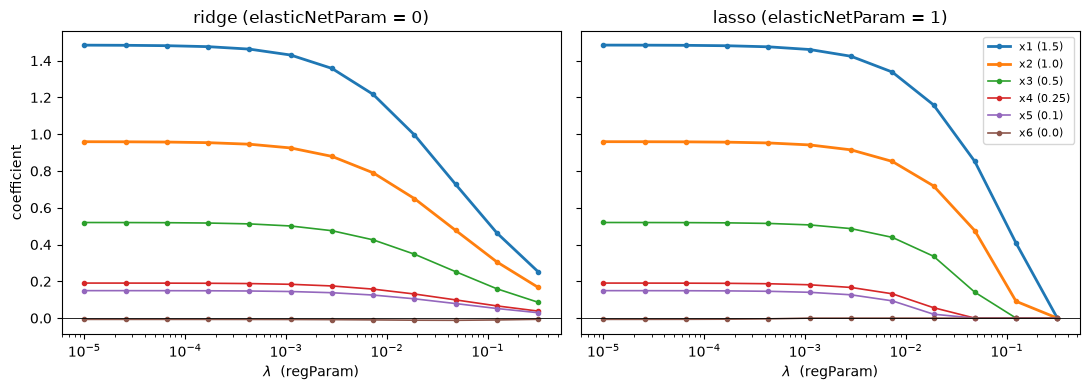

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, coefs) in zip(axes, paths.items()):
    for j in range(coefs.shape[1]):
        ax.plot(lambdas, coefs[:, j],
                marker='o', markersize=3,
                lw=2.0 if j < 2 else 1.2,
                label=NAMES[j])
    ax.set_xscale('log')
    ax.axhline(0, color='k', lw=0.6)
    ax.set_xlabel(r"$\lambda$  (regParam)")
    ax.set_title(name)
axes[0].set_ylabel("coefficient")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

In [12]:
zeros = pd.DataFrame({
    "lambda": np.round(lambdas, 5),
    "ridge: exact zeros": [(c == 0).sum() for c in paths["ridge (elasticNetParam = 0)"]],
    "lasso: exact zeros": [(c == 0).sum() for c in paths["lasso (elasticNetParam = 1)"]],
})
print(zeros.to_string(index=False))

 lambda  ridge: exact zeros  lasso: exact zeros
0.00001                   0                   0
0.00003                   0                   0
0.00007                   0                   0
0.00017                   0                   0
0.00043                   0                   0
0.00111                   0                   1
0.00285                   0                   1
0.00731                   0                   1
0.01874                   0                   1
0.04806                   0                   3
0.12328                   0                   4
0.31623                   0                   6


Read the two panels together.

**Ridge shrinks everything at once.** Every curve slides toward zero as $\lambda$ grows, the noise
features faster than the signal features, and not one of them arrives. The count of exact zeros
stays at zero for every $\lambda$ in the sweep. Every predictor is retained, with a smaller
coefficient; nothing is selected out.

**The lasso removes them one at a time.** Each curve reaches zero at its own value of $\lambda$ and
**stays** there, and they go in order of how little they contribute — `x6`, which was generated
with a true coefficient of zero, goes first, and `x1`, generated with the largest, goes last. That
ordering is not built in anywhere; it is the penalty discovering the structure of the data. That is feature selection performed by the
optimizer, and the count in the right-hand column climbs in steps as $\lambda$ increases.

Between the two, `elasticNetParam` interpolates: the sweep below holds $\lambda$ fixed and varies
the mix.

In [13]:
mix = []
for alpha in (0.0, 0.25, 0.5, 0.75, 1.0):
    b = train(rdd6, n_iter=120, learningRate=1.0, reg=0.05, alpha=alpha, proximal=True)
    mix.append({"elasticNetParam": alpha,
                **{NAMES[j]: round(float(b[j]), 4) for j in range(len(NAMES) - 1)},
                "exact zeros": int((b[:-1] == 0).sum())})
print(pd.DataFrame(mix).to_string(index=False))

 elasticNetParam  x1 (1.5)  x2 (1.0)  x3 (0.5)  x4 (0.25)  x5 (0.1)  x6 (0.0)  exact zeros
            0.00    0.7157    0.4696    0.2483     0.0976    0.0779   -0.0118            0
            0.25    0.7359    0.4679    0.2267     0.0620    0.0397   -0.0000            1
            0.50    0.7611    0.4667    0.2013     0.0193    0.0000   -0.0000            2
            0.75    0.7933    0.4647    0.1699     0.0000    0.0000   -0.0000            3
            1.00    0.8362    0.4626    0.1302     0.0000    0.0000   -0.0000            3


---

## 5. The intercept, and Exercise 8(c)

The two lines this notebook started from penalize **every** entry of the parameter vector, the
intercept included. Standard practice excludes it: shrinking an intercept toward zero moves the
decision boundary rather than reducing the complexity of the model, and there is no reason to
prefer a boundary near the origin.

The training function takes `penalize_intercept`, which zeroes the penalty's mask on the last
entry. This is Exercise 8(c), and the difference is visible in one number.

In [14]:
with_it = train(rdd6, n_iter=200, reg=0.1, alpha=0.0, penalize_intercept=True)
without = train(rdd6, n_iter=200, reg=0.1, alpha=0.0, penalize_intercept=False)

print(pd.DataFrame({"feature": NAMES,
                    "penalizing the intercept": np.round(with_it, 4),
                    "excluding the intercept": np.round(without, 4)}).to_string(index=False))

  feature  penalizing the intercept  excluding the intercept
 x1 (1.5)                    0.5185                   0.5374
 x2 (1.0)                    0.3417                   0.3537
 x3 (0.5)                    0.1789                   0.1852
x4 (0.25)                    0.0734                   0.0769
 x5 (0.1)                    0.0580                   0.0602
 x6 (0.0)                   -0.0107                  -0.0106
intercept                   -0.3478                  -0.6741


---

## 6. The same two knobs on the estimator

`regParam` is $\lambda$ and `elasticNetParam` is $\alpha$. Exercise 8(d) asks for an elastic net of
three parts $\ell_2$ to one part $\ell_1$ at an overall strength of $0.1$, which is the last row
below.

In [15]:
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.linalg import Vectors

df6 = rdd6.map(lambda r: (float(r[0]), Vectors.dense(r[1][:-1]))).toDF(["label", "features"])
df6.cache(); df6.count()

out = []
for lam, alpha, note in [(0.0, 0.0, "unregularized"),
                         (0.05, 0.0, "ridge"),
                         (0.05, 1.0, "lasso"),
                         (0.1, 0.25, "elastic net, 3 parts L2 to 1 part L1")]:
    m = LogisticRegression(regParam=lam, elasticNetParam=alpha).fit(df6)
    c = np.array(m.coefficients)
    out.append({"regParam": lam, "elasticNetParam": alpha, "note": note,
                "exact zeros": int((c == 0).sum()),
                "coefficients": np.round(c, 3)})

print(pd.DataFrame(out).to_string(index=False))

 regParam  elasticNetParam                                 note  exact zeros                               coefficients
     0.00             0.00                        unregularized            0 [1.487, 0.961, 0.521, 0.191, 0.15, -0.007]
     0.05             0.00                                ridge            0 [0.948, 0.619, 0.33, 0.127, 0.101, -0.011]
     0.05             1.00                                lasso            3       [0.893, 0.493, 0.139, 0.0, 0.0, 0.0]
     0.10             0.25 elastic net, 3 parts L2 to 1 part L1            2     [0.709, 0.435, 0.187, 0.021, 0.0, 0.0]


The estimator reaches the same conclusions the hand-written loop did: ridge shrinks and keeps every
coefficient, the lasso zeroes the noise features outright, and the elastic net does some of each.
It gets there with OWL-QN rather than a proximal gradient step, but the shape of the answer is a
property of the penalty and not of the optimizer that finds it.

---

## Conclusion

The learning objective has two terms and only one of them touches the data. The loss is a sum over
training examples and is computed across the cluster; the penalty depends on the parameter vector
alone, which already lives on the driver, so adding it costs two lines and no communication at all.
That asymmetry is why regularization is essentially free in a distributed setting, however
expensive the loss is.

Which penalty is chosen is not free, and the cost is paid by the optimizer rather than by the
network. $\ell_2$ is smooth, so any gradient method handles it and the closed form survives.
$\ell_1$ is not differentiable at zero, which is exactly where its usefulness lives, and a plain
gradient step therefore produces coefficients that hover near zero without ever reaching it. A
proximal step reaches it; so does OWL-QN, which is what Spark switches to. The apparently innocuous
`elasticNetParam` therefore selects two things at once: what is added to the objective, and which
algorithm is allowed to minimize it.